# 08 · Recalled causes and years of drying (Fig. 6)
Among the 1,521 dried sources: reported causes and years (first summarised by Pandit et al. 2026),
cause-specific predictability, and the Knox space-time test of same-year reporting within against
across wards. Recalled causes and years are survey responses reconstructed from memory, not verified
events. The ward ICC of these attributes is computed with the typology in notebook 05 (`un_dried_icc.csv`)
and against the strengthened nulls in notebook 06 (`x10_strengthened_nulls.csv`); both are shown here.

Running this notebook reproduces the descriptive tables, the cause-specific AUC and the Knox test.

In [1]:
import logging, os, sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s [%(levelname)s] %(message)s", stream=sys.stdout, force=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

M = ROOT / "results/metrics"
F = ROOT / "results/figures"

def table(name, **kw):
    return pd.read_csv(M / name, **kw).round(4)

def fig(name, width=1100):
    display(Image(filename=str(F / name), width=width))

In [2]:
from src.descriptive import run_descriptive
run_descriptive()

2026-11-10 16:02:59,683 [INFO] 
                                                    0
n_dried                                   1521.000000
n_valid_year                              1513.000000
n_dried_in_2072BS                          538.000000
share_dried_in_2072BS                        0.353715
share_earthquake_attributed_among_2072BS     0.840149
n_earthquake_attributed                    521.000000
share_of_earthquake_attributed_in_2072BS     0.867562
share_dried_before_2072BS                    0.405654
share_dried_after_2072BS                     0.235371


2026-11-10 16:03:15,581 [INFO] 
                 model           dried_subset  n_dried  n_active  roc_auc  ci_low  ci_high
0  Logistic Regression              all dried     1521      4168    0.691   0.675    0.706
1  Logistic Regression  earthquake-attributed      521      4168    0.650   0.624    0.675
2  Logistic Regression           other causes     1000      4168    0.713   0.696    0.730
3             CatBoost              all dried     1521      4168    0.700   0.685    0.715
4             CatBoost  earthquake-attributed      521      4168    0.678   0.653    0.703
5             CatBoost           other causes     1000      4168    0.712   0.693    0.728


(   n_dried  n_valid_year  n_dried_in_2072BS  share_dried_in_2072BS  share_earthquake_attributed_among_2072BS  n_earthquake_attributed  share_of_earthquake_attributed_in_2072BS  \
 0     1521          1513                538               0.353715                                  0.840149                      521                                  0.867562   
 
    share_dried_before_2072BS  share_dried_after_2072BS  
 0                   0.405654                  0.235371  ,
                  model           dried_subset  n_dried  n_active   roc_auc    ci_low   ci_high
 0  Logistic Regression              all dried     1521      4168  0.691008  0.675286  0.706089
 1  Logistic Regression  earthquake-attributed      521      4168  0.649700  0.623516  0.674621
 2  Logistic Regression           other causes     1000      4168  0.712529  0.695955  0.730080
 3             CatBoost              all dried     1521      4168  0.700184  0.684769  0.714925
 4             CatBoost  earthquake-attri

In [3]:
from src.dataset import load_master, coords_to_metric
from src.spatial_analysis import knox_test

df = load_master()
coords = coords_to_metric(df.latitude.to_numpy(), df.longitude.to_numpy())
k = knox_test(df, coords)
k[k.time_years == 0].round(3)

,cohort,pairs,n_sources,space_m,time_years,n_close_pairs,observed,expected,ratio_obs_exp,p_value
0,all dried with valid year,all pairs,1513,250,0,2242,529,342.836,1.543,0.001
2,all dried with valid year,same ward,1513,250,0,2046,507,315.555,1.607,0.001
4,all dried with valid year,different ward,1513,250,0,196,22,29.948,0.735,0.824
6,all dried with valid year,all pairs,1513,500,0,5597,1219,856.313,1.424,0.001
8,all dried with valid year,same ward,1513,500,0,4630,1111,707.554,1.570,0.001
10,all dried with valid year,different ward,1513,500,0,967,108,148.714,0.726,0.948
12,all dried with valid year,all pairs,1513,1000,0,13904,2701,2135.936,1.265,0.001
14,all dried with valid year,same ward,1513,1000,0,10168,2309,1561.311,1.479,0.001
16,all dried with valid year,different ward,1513,1000,0,3736,392,572.546,0.685,1.000
18,excluding 2072 BS cohort,all pairs,975,250,0,1512,219,98.858,2.215,0.001


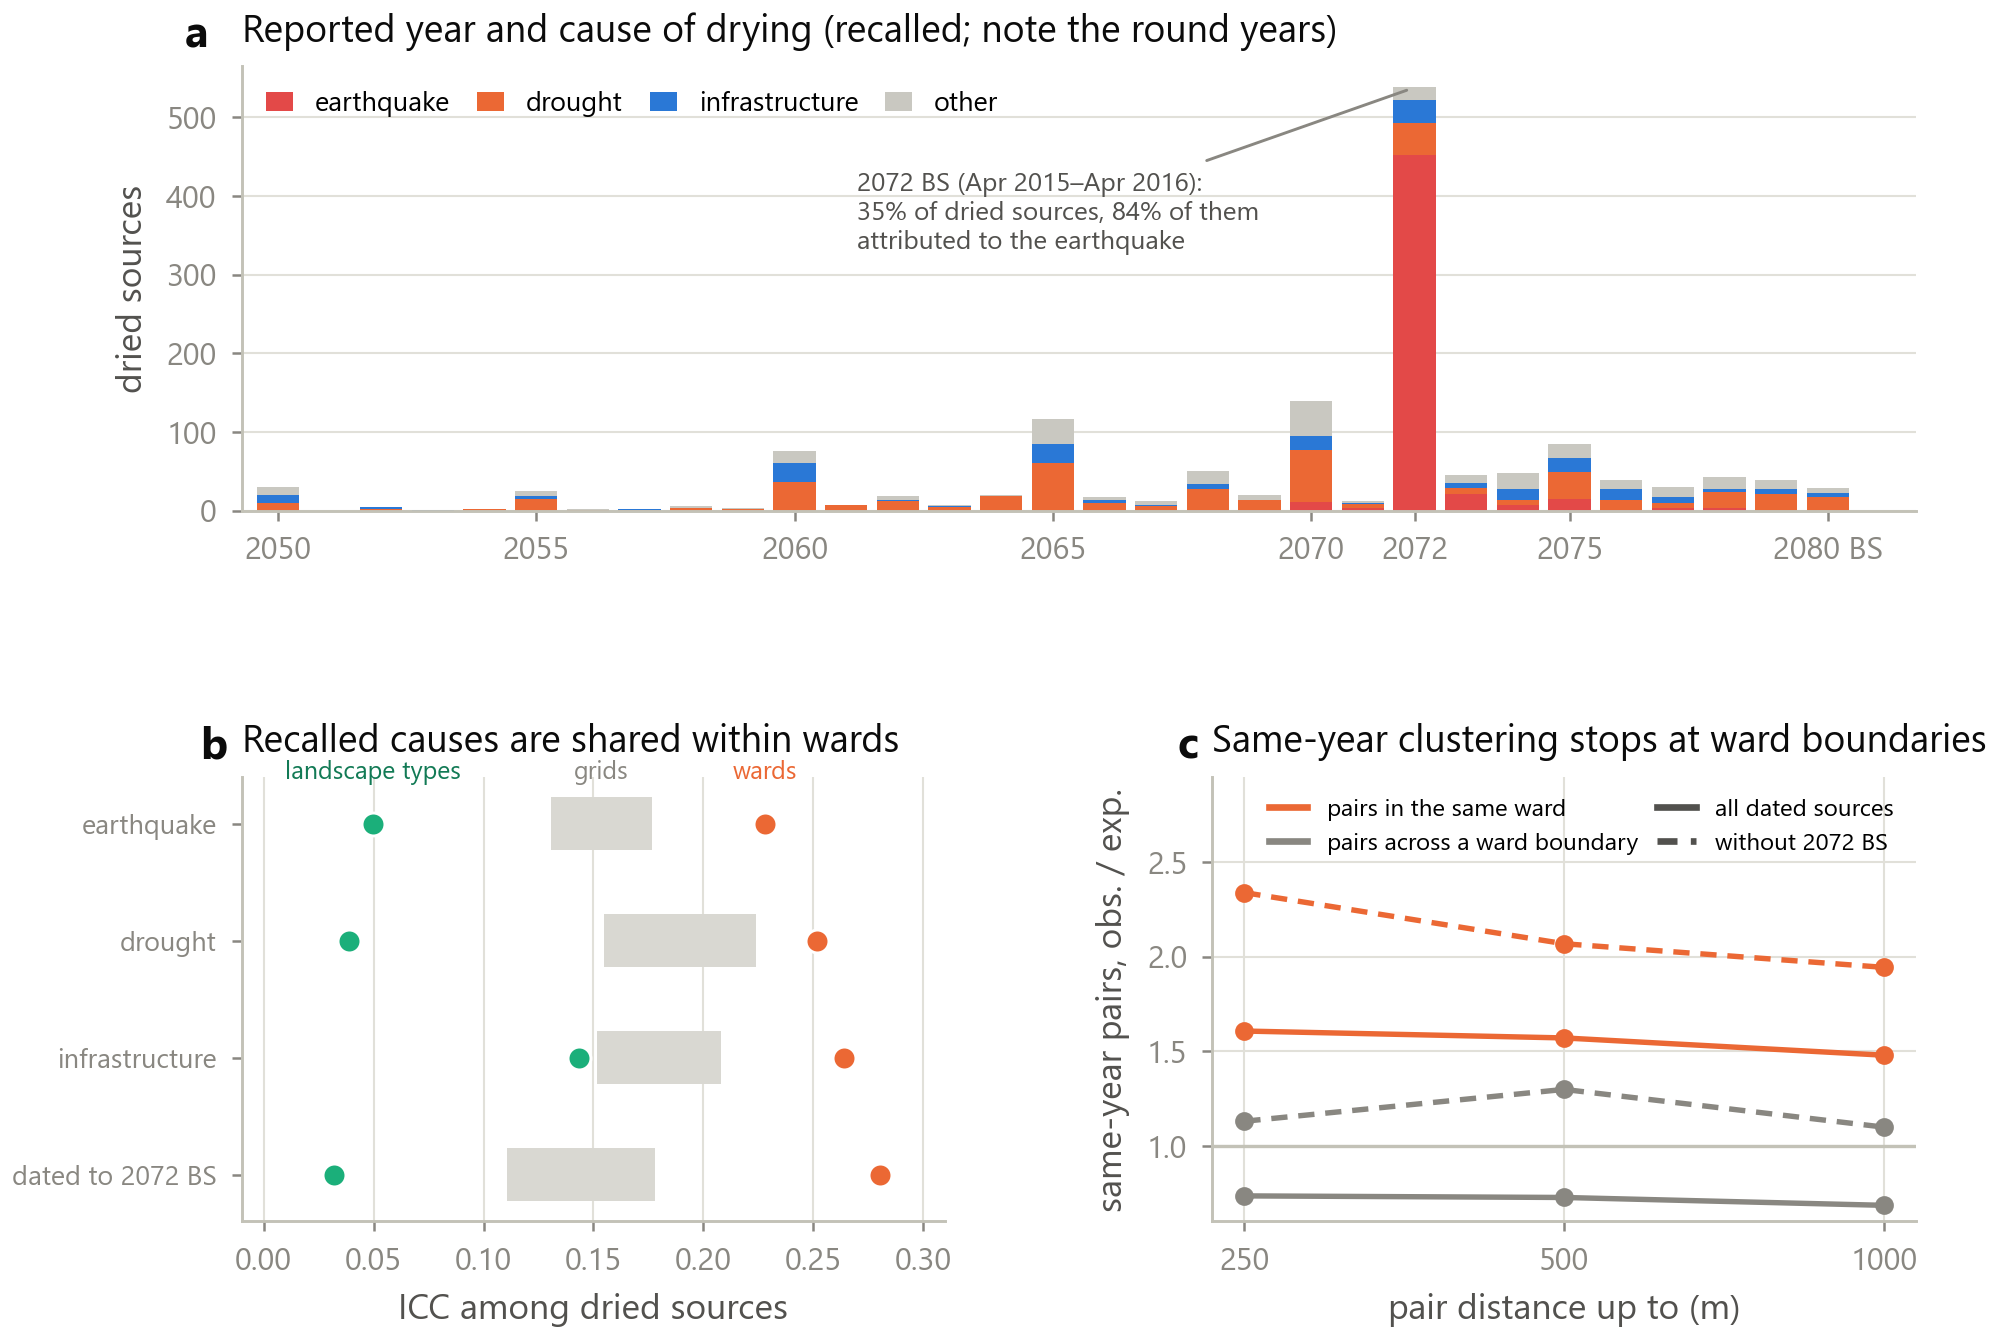

In [4]:
fig("fig6_recalled.png")

In [5]:
display(table("drying_reasons.csv"))
table("drying_timing_summary.csv")

,reported_reason,n_dried,share
0,earthquake,521,0.3425
1,drought,477,0.3136
2,infrastructure_development,240,0.1578
3,natural_disaster,113,0.0743
4,source_neglected,96,0.0631
5,source_disruption,46,0.0302
6,deforestation,16,0.0105
7,reduced precipitation,8,0.0053
8,wa reason,3,0.0020
9,pine plantation,1,0.0007


,n_dried,n_valid_year,n_dried_in_2072BS,share_dried_in_2072BS,share_earthquake_attributed_among_2072BS,n_earthquake_attributed,share_of_earthquake_attributed_in_2072BS,share_dried_before_2072BS,share_dried_after_2072BS
0,1521,1513,538,0.3537,0.8401,521,0.8676,0.4057,0.2354


## Ward clustering of recalled attributes (computed in notebooks 05 and 06)

In [6]:
display(table("un_dried_icc.csv"))
x = table("x10_strengthened_nulls.csv")
x[x.outcome.str.contains("attribution|2072")][["subset", "outcome", "null", "obs", "null_max", "p_one_sided"]]

,outcome,share,unit,n_units,icc,grid_icc_mean,grid_icc_q025,grid_icc_q975,p_above_grid,cramers_v
0,earthquake attributed,0.3425,ward,75,0.2283,0.1518,0.1308,0.1767,0.005,0.4624
1,earthquake attributed,0.3425,landscape type,8,0.0495,NaN,NaN,NaN,NaN,0.1996
2,drought attributed,0.3136,ward,75,0.2515,0.1870,0.1549,0.2240,0.005,0.4854
3,drought attributed,0.3136,landscape type,8,0.0387,NaN,NaN,NaN,NaN,0.1761
4,infrastructure attributed,0.1578,ward,75,0.2642,0.1801,0.1517,0.2079,0.005,0.4976
5,infrastructure attributed,0.1578,landscape type,8,0.1436,NaN,NaN,NaN,NaN,0.3431
6,dated 2072 BS,0.3537,ward,75,0.2802,0.1484,0.1105,0.1779,0.005,0.5125
7,dated 2072 BS,0.3537,landscape type,8,0.0322,NaN,NaN,NaN,NaN,0.1605


,subset,outcome,null,obs,null_max,p_one_sided
3,all sources,earthquake attribution,rotated matched grids,0.2283,0.1848,0.001
4,all sources,drought attribution,rotated matched grids,0.2515,0.2232,0.001
5,all sources,infrastructure attribution,rotated matched grids,0.2642,0.2211,0.001
6,all sources,dated to 2072 BS,rotated matched grids,0.2802,0.1953,0.001
10,all sources,earthquake attribution,contiguous size-matched regions,0.2283,0.1491,0.001
11,all sources,drought attribution,contiguous size-matched regions,0.2515,0.1863,0.001
12,all sources,infrastructure attribution,contiguous size-matched regions,0.2642,0.2183,0.001
13,all sources,dated to 2072 BS,contiguous size-matched regions,0.2802,0.1578,0.001
17,all sources,earthquake attribution,contiguous size-matched regions within municipality,0.2283,0.1587,0.001
18,all sources,drought attribution,contiguous size-matched regions within municipality,0.2515,0.2133,0.001
